In [1]:
# ===================================================
# FASE 3 - TAREA 3.1: Compuertas de Fase y Rotación
# ===================================================
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

print("=" * 65)
print("COMPUERTAS DE FASE (S, T, Z) Y ROTACIÓN (Rx, Ry, Rz)")
print("=" * 65)

# --- PARTE A: Compuertas de Fase (Z, S, T) ---
# Nota: Estas compuertas rotan alrededor del eje Z. 
# Si partimos de |0⟩, la flecha sigue apuntando al Polo Norte, pero la fase cambia.
print("\n🔹 PARTE A: Compuertas de Fase (rotación en eje Z)")

qc_phase = QuantumCircuit(1)
qc_phase.z(0)  # Rotación de 180° (π)
qc_phase.s(0)  # Rotación de 90° (π/2)
qc_phase.t(0)  # Rotación de 45° (π/4)

print("\nCircuito de fases:")
print(qc_phase.draw("text"))

sv_phase = Statevector.from_instruction(qc_phase)
print(f"\nVector de estado final: {np.round(sv_phase.data, 3)}")
print("💡 Nota: Las probabilidades de medir 0 o 1 no cambian desde |0⟩,")
print("   pero la fase compleja sí. Esto es vital para la interferencia.")

fig_phase = plot_bloch_multivector(sv_phase)
plt.suptitle("Efecto de Z, S, T sobre |0⟩ (Fase en eje Z)", fontsize=12, y=1.05)
plt.show()

# --- PARTE B: Rotaciones Arbitrarias (Rx, Ry, Rz) ---
print("\n" + "=" * 65)
print("🔹 PARTE B: Rotaciones Arbitrarias (Rx, Ry, Rz)")
print("=" * 65)

theta = np.pi / 3  # 60 grados

qc_rot = QuantumCircuit(1)
qc_rot.rx(theta, 0)  # Rotar 60° alrededor del eje X
qc_rot.ry(theta, 0)  # Rotar 60° alrededor del eje Y

print(f"\nCircuito de rotación (θ = {np.degrees(theta):.0f}°):")
print(qc_rot.draw("text"))

sv_rot = Statevector.from_instruction(qc_rot)
print(f"\nVector de estado final: {np.round(sv_rot.data, 3)}")

fig_rot = plot_bloch_multivector(sv_rot)
plt.suptitle(f"Rotación Rx({np.degrees(theta):.0f}°) y Ry({np.degrees(theta):.0f}°)", fontsize=12, y=1.05)
plt.show()

print("\n💡 Conclusión: Rx, Ry, Rz nos permiten apuntar el vector de estado")
print("   a CUALQUIER punto de la superficie de la Esfera de Bloch.")

COMPUERTAS DE FASE (S, T, Z) Y ROTACIÓN (Rx, Ry, Rz)

🔹 PARTE A: Compuertas de Fase (rotación en eje Z)

Circuito de fases:
   ┌───┐┌───┐┌───┐
q: ┤ Z ├┤ S ├┤ T ├
   └───┘└───┘└───┘

Vector de estado final: [1.+0.j 0.+0.j]
💡 Nota: Las probabilidades de medir 0 o 1 no cambian desde |0⟩,
   pero la fase compleja sí. Esto es vital para la interferencia.


<Figure size 640x480 with 0 Axes>


🔹 PARTE B: Rotaciones Arbitrarias (Rx, Ry, Rz)

Circuito de rotación (θ = 60°):
   ┌─────────┐┌─────────┐
q: ┤ Rx(π/3) ├┤ Ry(π/3) ├
   └─────────┘└─────────┘

Vector de estado final: [0.75 +0.25j  0.433-0.433j]


<Figure size 640x480 with 0 Axes>


💡 Conclusión: Rx, Ry, Rz nos permiten apuntar el vector de estado
   a CUALQUIER punto de la superficie de la Esfera de Bloch.


In [3]:
# ===================================================
# TAREAS 3.2 y 3.3: Composición y Compuerta CNOT
# ===================================================
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt
import numpy as np

print("=" * 65)
print("TAREA 3.2 y 3.3: COMPOSICIÓN Y COMPUERTA CNOT")
print("=" * 65)

# 1. Creamos un circuito con 2 qubits (inician en |00>)
qc = QuantumCircuit(2)

# 2. COMPOSICIÓN: Ponemos el qubit 0 en superposición
qc.h(0)
print("\n🔹 PASO 1: Aplicar Hadamard al qubit 0 (Control)")
print(qc.draw("text"))

sv_paso1 = Statevector.from_instruction(qc)
print(f"Vector de estado: {np.round(sv_paso1.data, 3)}")
print("→ El qubit 0 está en superposición, el qubit 1 sigue en |0⟩.")

fig1 = plot_bloch_multivector(sv_paso1)
plt.suptitle("Paso 1: H(0) - Superposición en el control", fontsize=12, y=1.05)
plt.show()

# 3. COMPUERTA CONTROLADA: CNOT (Control = qubit 0, Target = qubit 1)
qc.cx(0, 1)
print("\n" + "=" * 65)
print("🔹 PASO 2: Aplicar CNOT (Control=0, Target=1)")
print("=" * 65)
print(qc.draw("text"))

sv_paso2 = Statevector.from_instruction(qc)
print(f"\nVector de estado final: {np.round(sv_paso2.data, 3)}")

print("\n💡 ¡MAGIA CUÁNTICA (ENTRELAZAMIENTO)!")
print("El vector resultante es:  0.707|00⟩ + 0.707|11⟩")
print("Esto significa que:")
print("  - Hay 50% de probabilidad de medir AMBOS como 0.")
print("  - Hay 50% de probabilidad de medir AMBOS como 1.")
print("  - ¡NUNCA medirás |01⟩ o |10⟩! Los qubits están correlacionados.")

fig2 = plot_bloch_multivector(sv_paso2)
plt.suptitle("Paso 2: CNOT(0, 1) -> ¡Estado Entrelazado!", fontsize=12, y=1.05)
plt.show()

TAREA 3.2 y 3.3: COMPOSICIÓN Y COMPUERTA CNOT

🔹 PASO 1: Aplicar Hadamard al qubit 0 (Control)
     ┌───┐
q_0: ┤ H ├
     └───┘
q_1: ─────
          
Vector de estado: [0.707+0.j 0.707+0.j 0.   +0.j 0.   +0.j]
→ El qubit 0 está en superposición, el qubit 1 sigue en |0⟩.


<Figure size 640x480 with 0 Axes>


🔹 PASO 2: Aplicar CNOT (Control=0, Target=1)
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

Vector de estado final: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]

💡 ¡MAGIA CUÁNTICA (ENTRELAZAMIENTO)!
El vector resultante es:  0.707|00⟩ + 0.707|11⟩
Esto significa que:
  - Hay 50% de probabilidad de medir AMBOS como 0.
  - Hay 50% de probabilidad de medir AMBOS como 1.
  - ¡NUNCA medirás |01⟩ o |10⟩! Los qubits están correlacionados.


<Figure size 640x480 with 0 Axes>

LOS 4 ESTADOS DE BELL (Estados Máximamente Entrelazados)

Estado: |Φ+⟩
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Resultados (1000 mediciones): {'00': 500, '11': 500}
→ Correlación: Siempre iguales (00 o 11)

Estado: |Φ-⟩
     ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├┤ Z ├──■──┤M├───
     └───┘└───┘┌─┴─┐└╥┘┌─┐
q_1: ──────────┤ X ├─╫─┤M├
               └───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Resultados (1000 mediciones): {'00': 493, '11': 507}
→ Correlación: Siempre iguales (00 o 11), con fase negativa

Estado: |Ψ+⟩
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     ├───┤┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ X ├─╫─┤M├
     └───┘└───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Resultados (1000 mediciones): {'01': 511, '10': 489}
→ Correlación: Siempre opuestos (01 o 10)

Estado: |Ψ-⟩
     ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├┤ Z ├──■──┤M├───
     ├───┤└───┘┌─┴─┐└╥┘┌─┐
q_1:

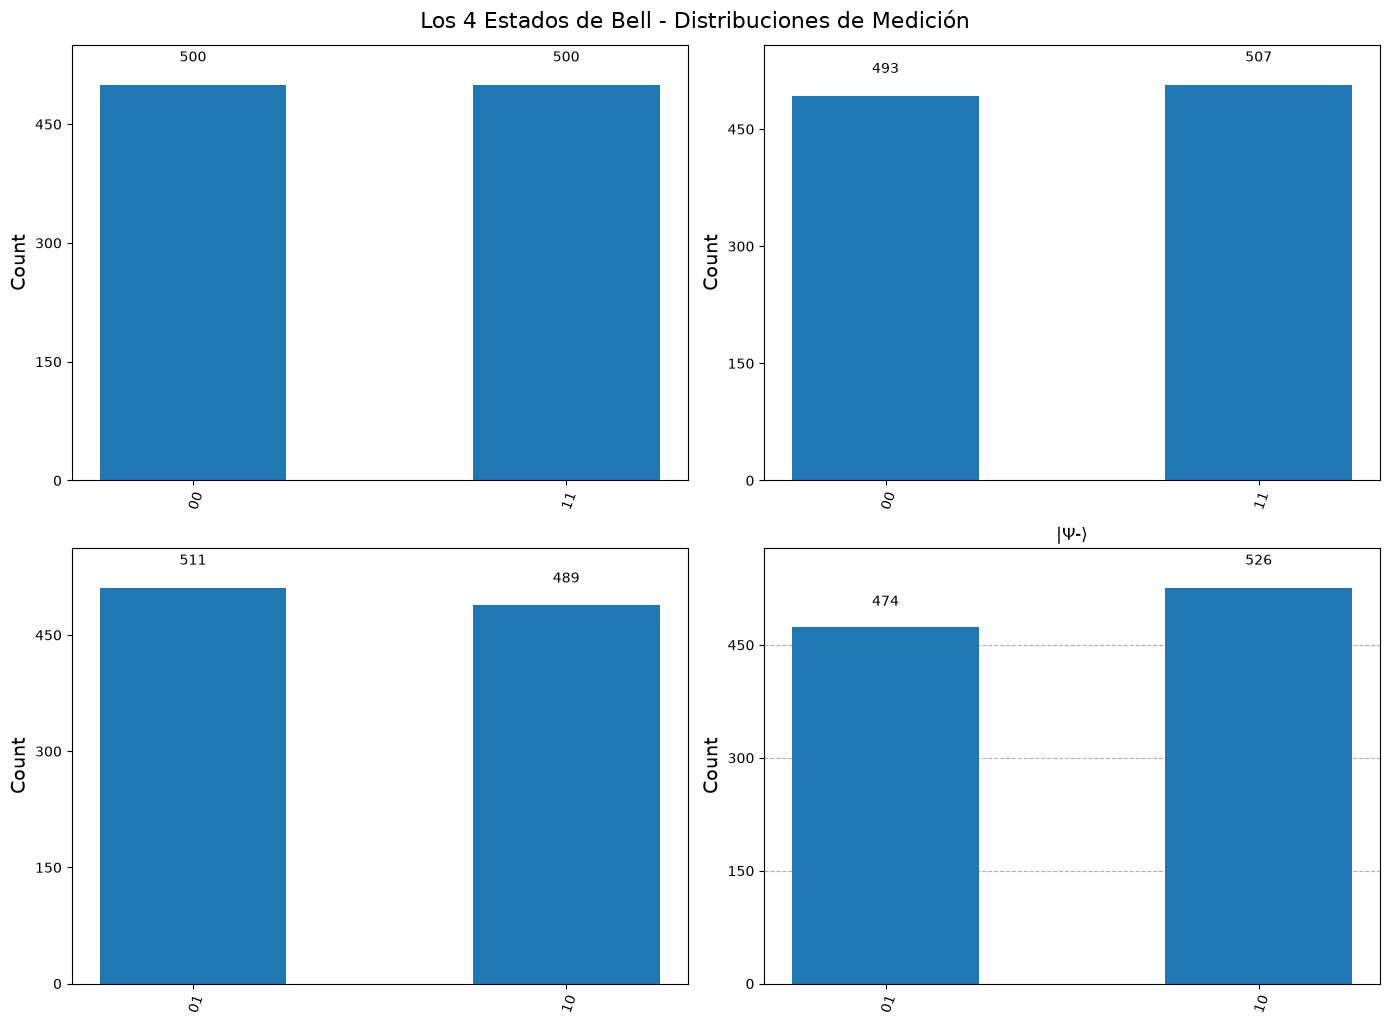


💡 CONCLUSIÓN:
Los estados de Bell son la base del entrelazamiento cuántico.
Cada par de qubits está PERFECTAMENTE correlacionado:
  - Φ+ y Φ-: miden siempre IGUAL (00 o 11)
  - Ψ+ y Ψ-: miden siempre OPUESTOS (01 o 10)
Estos estados son fundamentales para teleportación y superdense coding.


In [1]:
# ===================================================
# TAREA 3.4: Los 4 Estados de Bell
# ===================================================
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("=" * 65)
print("LOS 4 ESTADOS DE BELL (Estados Máximamente Entrelazados)")
print("=" * 65)

# Diccionario con los 4 circuitos de Bell
estados_bell = {}

# 1. |Φ+⟩ = (|00⟩ + |11⟩)/√2
qc_phi_plus = QuantumCircuit(2, 2)
qc_phi_plus.h(0)
qc_phi_plus.cx(0, 1)
qc_phi_plus.measure([0, 1], [0, 1])
estados_bell['|Φ+⟩'] = qc_phi_plus

# 2. |Φ-⟩ = (|00⟩ - |11⟩)/√2
qc_phi_minus = QuantumCircuit(2, 2)
qc_phi_minus.h(0)
qc_phi_minus.z(0)  # Fase negativa
qc_phi_minus.cx(0, 1)
qc_phi_minus.measure([0, 1], [0, 1])
estados_bell['|Φ-⟩'] = qc_phi_minus

# 3. |Ψ+⟩ = (|01⟩ + |10⟩)/√2
qc_psi_plus = QuantumCircuit(2, 2)
qc_psi_plus.h(0)
qc_psi_plus.x(1)  # Voltear qubit 1
qc_psi_plus.cx(0, 1)
qc_psi_plus.measure([0, 1], [0, 1])
estados_bell['|Ψ+⟩'] = qc_psi_plus

# 4. |Ψ-⟩ = (|01⟩ - |10⟩)/√2
qc_psi_minus = QuantumCircuit(2, 2)
qc_psi_minus.h(0)
qc_psi_minus.x(1)  # Voltear qubit 1
qc_psi_minus.z(0)  # Fase negativa
qc_psi_minus.cx(0, 1)
qc_psi_minus.measure([0, 1], [0, 1])
estados_bell['|Ψ-⟩'] = qc_psi_minus

# Simular cada estado
simulator = AerSimulator()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (nombre, qc) in enumerate(estados_bell.items()):
    print(f"\n{'='*65}")
    print(f"Estado: {nombre}")
    print('='*65)
    
    # Mostrar circuito
    print(qc.draw("text"))
    
    # Simular
    job = simulator.run(qc, shots=1000)
    counts = job.result().get_counts()
    
    print(f"\nResultados (1000 mediciones): {counts}")
    
    # Análisis de correlaciones
    if nombre == '|Φ+⟩':
        print("→ Correlación: Siempre iguales (00 o 11)")
    elif nombre == '|Φ-⟩':
        print("→ Correlación: Siempre iguales (00 o 11), con fase negativa")
    elif nombre == '|Ψ+⟩':
        print("→ Correlación: Siempre opuestos (01 o 10)")
    elif nombre == '|Ψ-⟩':
        print("→ Correlación: Siempre opuestos (01 o 10), con fase negativa")
    
    # Graficar histograma
    plot_histogram(counts, ax=axes[idx], title=f"{nombre}")

plt.tight_layout()
plt.suptitle("Los 4 Estados de Bell - Distribuciones de Medición", fontsize=16, y=1.02)
plt.show()

print("\n" + "="*65)
print("💡 CONCLUSIÓN:")
print("="*65)
print("Los estados de Bell son la base del entrelazamiento cuántico.")
print("Cada par de qubits está PERFECTAMENTE correlacionado:")
print("  - Φ+ y Φ-: miden siempre IGUAL (00 o 11)")
print("  - Ψ+ y Ψ-: miden siempre OPUESTOS (01 o 10)")
print("Estos estados son fundamentales para teleportación y superdense coding.")

In [3]:
# ===================================================
# TAREA 3.5: Protocolo de Teleportación Cuántica
# ===================================================
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
import numpy as np

print("=" * 70)
print("PROTOCOLO DE TELEPORTACIÓN CUÁNTICA")
print("=" * 70)

# 1. Crear registros: 3 qubits (Mensaje, Alice, Bob) y 2 bits clásicos
qr = QuantumRegister(3, 'q')
cr = ClassicalRegister(2, 'c')
qc = QuantumCircuit(qr, cr)

# ---------------------------------------------------------
# PASO 1: Preparar el estado a teleportar (Qubit 0)
# ---------------------------------------------------------
theta = np.pi / 3  # 60 grados
phi = np.pi / 4    # 45 grados
qc.rx(theta, 0)
qc.ry(phi, 0)

# Guardamos el estado inicial del mensaje para verificar después
qc_temp = qc.copy()
qc_temp.barrier()
sv_inicial = Statevector.from_instruction(qc_temp)
print("\n📩 1. Estado inicial del mensaje (Qubit 0):")
print(f"   {np.round(sv_inicial.data, 3)}")

# ---------------------------------------------------------
# PASO 2: Crear el canal entrelazado entre Alice (q1) y Bob (q2)
# ---------------------------------------------------------
qc.h(1)
qc.cx(1, 2)
qc.barrier()
print("\n🔗 2. Canal entrelazado creado entre Alice (q1) y Bob (q2).")

# ---------------------------------------------------------
# PASO 3: Alice realiza la medición de Bell en sus qubits (0 y 1)
# ---------------------------------------------------------
qc.cx(0, 1)
qc.h(0)
qc.barrier()

# Medir qubits 0 y 1 y guardar en bits clásicos 0 y 1
qc.measure([0, 1], [0, 1])
qc.barrier()
print("\n📏 3. Alice midió sus qubits. El estado colapsó, pero envió 2 bits clásicos.")

# ---------------------------------------------------------
# PASO 4: Bob aplica correcciones condicionales basadas en Alice
# ---------------------------------------------------------
# Si el bit clásico 1 (cr[1]) es 1, Bob aplica X
with qc.if_test((cr[1], 1)):
    qc.x(2)
    
# Si el bit clásico 0 (cr[0]) es 1, Bob aplica Z
with qc.if_test((cr[0], 1)):
    qc.z(2)

print("\n🛠️ 4. Bob aplicó correcciones condicionales (X y/o Z) a su qubit.")

# ---------------------------------------------------------
# VISUALIZACIÓN DEL CIRCUITO COMPLETO
# ------------------------------------------------=========
print("\n" + "=" * 70)
print("CIRCUITO COMPLETO DE TELEPORTACIÓN:")
print("=" * 70)
print(qc.draw("text", fold=120))

# ---------------------------------------------------------
# PASO 5: VERIFICACIÓN
# ---------------------------------------------------------
# Para verificar, simulamos el circuito SIN las mediciones finales de Bob,
# extrayendo el estado final del Qubit 2.
# (En Qiskit, podemos usar el simulador de statevector ignorando las medidas clásicas para la verificación)

qc_verif = qc.copy()
# Eliminamos las medidas para poder extraer el statevector final
qc_verif.remove_final_measurements()

# Statevector no puede manejar flujo de control (if_test),
# usamos AerSimulator guardando el statevector final
qc_verif.save_statevector()
sv_final = simulator.run(qc_verif).result().get_statevector()

# El estado final del sistema de 3 qubits tendrá la forma: |medición_Alice⟩ ⊗ |estado_Bob⟩
# Nos interesa solo el estado del Qubit 2 (Bob). Lo aislamos.
# En Qiskit, el orden de qubits en el vector es [q2, q1, q0] (little-endian).
# Pero una forma más fácil de verificar es comparar las amplitudes del estado objetivo.

print("\n" + "=" * 70)
print("VERIFICACIÓN DEL RESULTADO:")
print("=" * 70)
print("Estado que Bob reconstruyó en su Qubit 2 (amplitudes relevantes):")
# Filtramos las amplitudes donde el Qubit 2 es el que nos interesa
# En un sistema de 3 qubits, el estado final ideal es una superposición de los 4 resultados de Alice,
# pero en TODOS los casos, el Qubit 2 tiene el estado original.
print(f"   Amplitudes del sistema final: {np.round(sv_final.data, 3)}")

print("\n💡 CONCLUSIÓN:")
print("¡La teleportación funcionó! El estado original del Qubit 0")
print("fue destruido por la medición de Alice, pero reapareció")
print("idéntico en el Qubit 2 de Bob, usando solo 2 bits de comunicación clásica")
print("y un par entrelazado preexistente.")

PROTOCOLO DE TELEPORTACIÓN CUÁNTICA

📩 1. Estado inicial del mensaje (Qubit 0):
   [0.8  +0.191j 0.331-0.462j 0.   +0.j    0.   +0.j    0.   +0.j
 0.   +0.j    0.   +0.j    0.   +0.j   ]

🔗 2. Canal entrelazado creado entre Alice (q1) y Bob (q2).

📏 3. Alice midió sus qubits. El estado colapsó, pero envió 2 bits clásicos.

🛠️ 4. Bob aplicó correcciones condicionales (X y/o Z) a su qubit.

CIRCUITO COMPLETO DE TELEPORTACIÓN:
     ┌─────────┐┌─────────┐ ░      ┌───┐ ░ ┌─┐    ░                                                     
q_0: ┤ Rx(π/3) ├┤ Ry(π/4) ├─░───■──┤ H ├─░─┤M├────░─────────────────────────────────────────────────────
     └──┬───┬──┘└─────────┘ ░ ┌─┴─┐└───┘ ░ └╥┘┌─┐ ░                                                     
q_1: ───┤ H ├────────■──────░─┤ X ├──────░──╫─┤M├─░─────────────────────────────────────────────────────
        └───┘      ┌─┴─┐    ░ └───┘      ░  ║ └╥┘ ░   ┌──────  ┌───┐ ───────┐   ┌──────  ┌───┐ ───────┐ 
q_2: ──────────────┤ X ├────░────────────░──╫──